# 02. 데이터 전처리 – 라벨 정제 · YOLO 변환 · 조합 단위 분할

EDA(01)에서 찾은 문제를 **사람 손으로 하나씩 고치지 않고, 규칙으로 탐지·수정·기록**한다.
같은 노트북을 다시 돌리면 같은 결과가 나오도록(재현성) 모든 수정은 코드와 로그로 남긴다.

| 단계 | 내용 | 구현 | 산출물 |
|---|---|---|---|
| 1 | 흩어진 JSON을 이미지 단위로 병합 | [`data.py`](../src/pilldet/data.py) | 원본 라벨 테이블 |
| 2 | 고전 영상처리(OpenCV)로 알약 영역 분할 | [`segment.py`](../src/pilldet/segment.py) | 알약 후보 박스 |
| 3 | 라벨 박스 vs 알약 영역 대조 → 라벨 감사 | [`clean.py`](../src/pilldet/clean.py) | 의심 라벨 목록 |
| 4 | 규칙 기반 수정: 범위 밖 · 엉뚱한 위치 · 누락 박스 | [`clean.py`](../src/pilldet/clean.py) | `label_fixes.csv` |
| 5 | 최종 무결성 검사 | [`clean.py`](../src/pilldet/clean.py) | – |
| 6 | 조합 단위 Stratified Group K-Fold | [`split.py`](../src/pilldet/split.py) | `folds.csv` |
| 7 | YOLO / COCO 내보내기 + 왕복 검증 | [`export.py`](../src/pilldet/export.py) | `datasets/pill/`, `annotations_clean.json` |

같은 과정을 노트북 없이 한 번에 돌리려면: `python scripts/prepare_data.py`

## 0. 환경 설정

In [1]:
import subprocess
import sys
from pathlib import Path

# 공통 코드(src/pilldet)를 불러온다. Kaggle에서는 GitHub 레포를 내려받는다.
REPO_URL = "https://github.com/lee-da-gyo/ai-project-01-pill-detection.git"
REPO_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if not (REPO_DIR / "src" / "pilldet").exists():
    REPO_DIR = Path("/kaggle/working/repo")
    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(REPO_DIR)], check=True)
sys.path.insert(0, str(REPO_DIR / "src"))

import inspect
from collections import Counter

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from PIL import Image

from pilldet import viz
from pilldet.boxes import yolo_to_xywh
from pilldet.clean import LabelCleaner, check_integrity
from pilldet.config import N_FOLDS, SEED, get_paths
from pilldet.data import list_train_images, load_annotations, load_rgb
from pilldet.export import build_class_map, export_coco, export_yolo, verify_yolo_roundtrip
from pilldet.segment import segment_pills
from pilldet.split import fold_summary, make_folds

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

P = get_paths(REPO_DIR)
KOREAN_OK = viz.setup_korean_font()
NAME_COL = "dl_name" if KOREAN_OK else "dl_name_en"


def save_fig(fig, name: str):
    viz.save_fig(fig, P.fig, name)


def show_source(obj):
    """패키지 함수의 실제 코드를 노트북에 그대로 보여 준다 (코드와 실행 결과를 한곳에서 확인)."""
    path = Path(inspect.getsourcefile(obj)).relative_to(REPO_DIR / "src")
    display(Markdown(f"**`src/{path.as_posix()}` → `{obj.__qualname__}`**\n```python\n{inspect.getsource(obj)}```"))


print("DATA_ROOT  :", P.data_root)
print("OUT_DIR    :", P.out)
print("DATASET_DIR:", P.dataset)

DATA_ROOT  : C:\Users\user\Desktop\ai_15기\###프로젝트\sprint_ai_project1_data
OUT_DIR    : C:\Users\user\Desktop\ai_15기\###프로젝트\pill-detection\reports
DATASET_DIR: C:\Users\user\Desktop\ai_15기\###프로젝트\pill-detection\datasets\pill


## 1. 라벨 병합
JSON 하나에 알약 하나씩 들어 있으므로 이미지 이름 기준으로 모은다.

In [2]:
raw = load_annotations(P.ann)
train_files = list_train_images(P.train_img)
assert raw["img_w"].nunique() == 1 and raw["img_h"].nunique() == 1, "이미지 크기가 섞여 있다"
IMG_W, IMG_H = int(raw["img_w"].iloc[0]), int(raw["img_h"].iloc[0])
print(f"이미지 {raw.file_name.nunique()}장 / 박스 {len(raw)}개 / 클래스 {raw.category_id.nunique()}개 / 크기 {IMG_W}×{IMG_H}")
raw[["file_name", "category_id", "dl_name", "x", "y", "w", "h", "camera_la"]].head()

이미지 232장 / 박스 763개 / 클래스 56개 / 크기 976×1280


,file_name,category_id,dl_name,x,y,w,h,camera_la
0,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,1900,보령부스파정 5mg,644.0,845.0,189.0,190.0,70
1,K-001900-016548-019607-029451_0_2_0_2_75_000_2...,1900,보령부스파정 5mg,148.0,241.0,181.0,181.0,75
2,K-001900-016548-019607-029451_0_2_0_2_90_000_2...,1900,보령부스파정 5mg,167.0,248.0,184.0,182.0,90
3,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,16548,가바토파정 100mg,144.0,799.0,239.0,239.0,70
4,K-001900-016548-019607-029451_0_2_0_2_75_000_2...,16548,가바토파정 100mg,578.0,222.0,233.0,226.0,75


## 2. 알약 영역 분할 (고전 영상처리)
라벨이 맞는지 검증하려면 **라벨과 독립적인 기준**이 필요하다. 배경이 단색에 가깝다는 EDA 결과를 이용해 알약을 분리한다.

1. 1/4로 축소 (속도, 잡음 감소)
2. Lab 색공간 변환. 사람 눈의 색 차이와 비슷한 거리를 준다
3. 큰 median blur로 **배경만 남긴 이미지**를 추정. 알약(약 60px)보다 큰 커널이라 알약이 지워진다
4. 원본과 배경의 색 거리 → Otsu 이진화 → 모폴로지로 잡음 제거
5. 연결 요소를 박스로 만든다. 가장자리에 닿는 영역(비네팅)과 작은 영역은 제외

한계: 반투명 연질캡슐(OMACOR)이나 배경과 색이 비슷한 알약은 일부만 잡힌다.
그래서 이 결과를 **정답으로 쓰지 않고, 라벨을 의심할 근거와 보완 후보로만** 쓴다.

In [3]:
show_source(segment_pills)

**`src/pilldet/segment.py` → `segment_pills`**
```python
def segment_pills(img_rgb: np.ndarray, scale: int = SEG_SCALE, blur: int = 101, min_area: int = 400) -> Segmentation:
    small = cv2.resize(img_rgb, None, fx=1 / scale, fy=1 / scale, interpolation=cv2.INTER_AREA)
    lab = cv2.cvtColor(small, cv2.COLOR_RGB2LAB)
    bg = np.dstack([cv2.medianBlur(lab[..., i], blur) for i in range(3)])
    dist = np.linalg.norm(lab.astype(np.float32) - bg.astype(np.float32), axis=2)
    dist = cv2.GaussianBlur(dist, (5, 5), 0)
    _, mask = cv2.threshold(np.clip(dist, 0, 255).astype(np.uint8), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((7, 7), np.uint8))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))

    _, _, stats, _ = cv2.connectedComponentsWithStats(mask)
    H, W = mask.shape
    boxes = []
    for x, y, w, h, a in stats[1:]:
        if a < min_area or x == 0 or y == 0 or x + w >= W or y + h >= H:
            continue
        boxes.append([x * scale, y * scale, (x + w) * scale, (y + h) * scale])
    return Segmentation(np.array(boxes, dtype=float).reshape(-1, 4), mask, dist, scale)
```

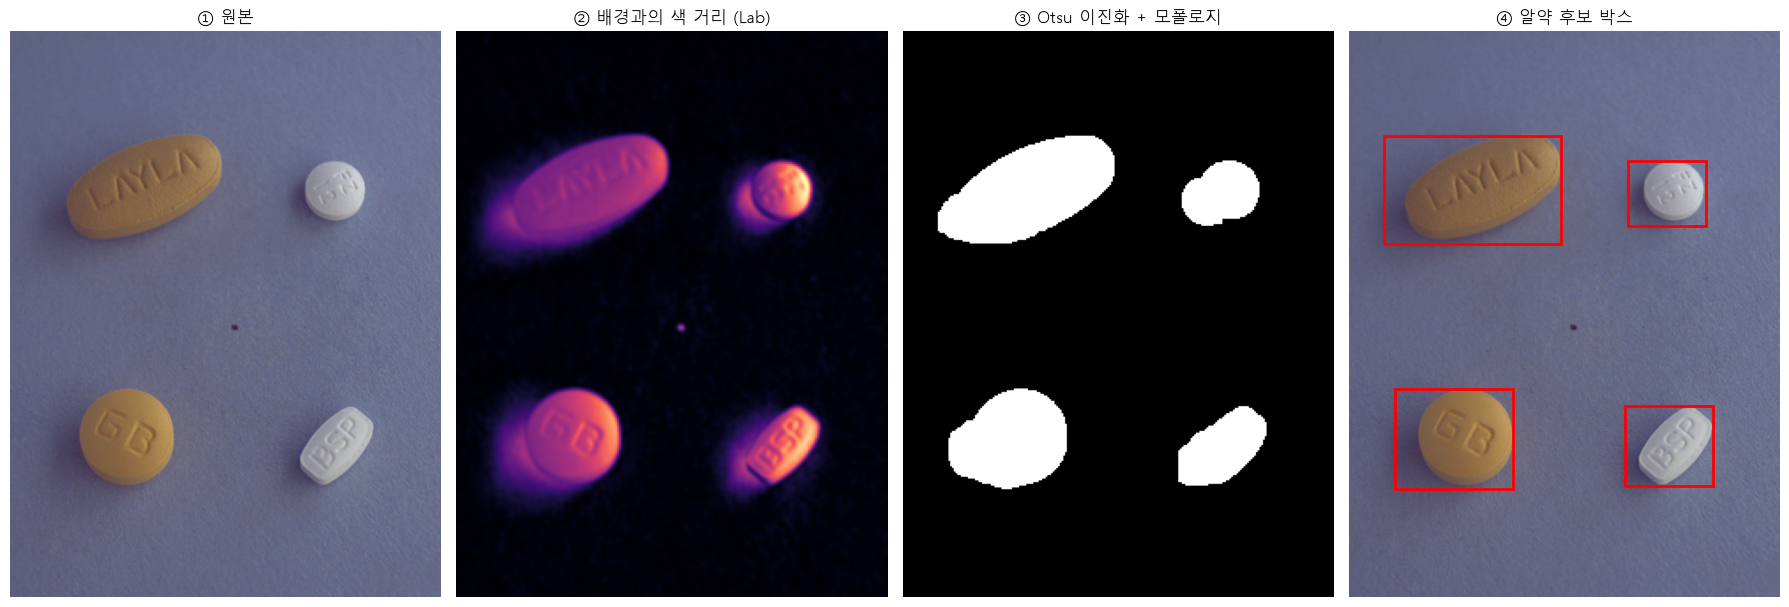

In [4]:
demo = train_files[0]
demo_img = load_rgb(P.train_img / demo)
seg = segment_pills(demo_img)
fig, axes = plt.subplots(1, 4, figsize=(18, 6))
axes[0].imshow(demo_img); axes[0].set_title("① 원본")
axes[1].imshow(seg.dist, cmap="magma"); axes[1].set_title("② 배경과의 색 거리 (Lab)")
axes[2].imshow(seg.mask, cmap="gray"); axes[2].set_title("③ Otsu 이진화 + 모폴로지")
axes[3].imshow(demo_img); axes[3].set_title("④ 알약 후보 박스")
for x1, y1, x2, y2 in seg.boxes:
    axes[3].add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="red", lw=2))
for ax in axes:
    ax.axis("off")
plt.tight_layout()
save_fig(fig, "14_segmentation_steps")
plt.show()

In [5]:
cleaner = LabelCleaner(raw, P.train_img)
cleaner.segment_all()
print("분할 완료:", len(cleaner.segs), "장 / 이미지당 후보 수:", dict(Counter(len(s.boxes) for s in cleaner.segs.values())))

분할 완료: 232 장 / 이미지당 후보 수: {4: 73, 5: 1, 3: 156, 2: 2}


## 3. 라벨 감사 (Label Audit)
각 라벨 박스에 대해 다음을 계산한다.
- `best_iou`: 가장 잘 겹치는 알약 후보와의 IoU
- `fg_ratio`: 박스 안에서 알약(전경) 픽셀이 차지하는 비율. **0에 가까우면 빈 배경에 그려진 박스**다
- `out_of_bounds`: 이미지 범위를 벗어났는지

       best_iou  fg_ratio
count   763.000   763.000
mean      0.792     0.623
std       0.103     0.106
min       0.000     0.000
25%       0.777     0.580
50%       0.808     0.639
75%       0.835     0.684
max       0.931     0.844

범위 밖 박스: 1 / 전경 비율 < 0.15 박스: 8


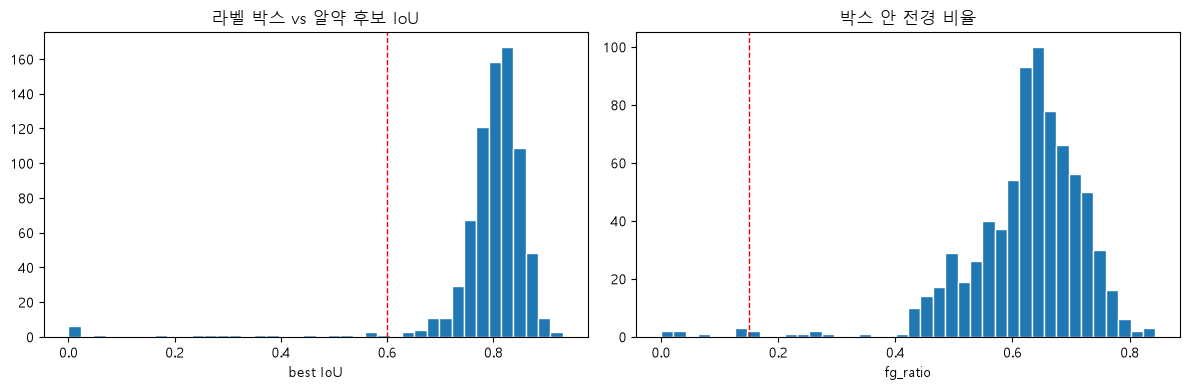

In [6]:
aud = cleaner.audit(raw)
print(aud[["best_iou", "fg_ratio"]].describe().round(3))
print("\n범위 밖 박스:", int(aud["out_of_bounds"].sum()), "/ 전경 비율 < 0.15 박스:", int((aud["fg_ratio"] < 0.15).sum()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(aud["best_iou"], bins=40, edgecolor="white"); axes[0].set(title="라벨 박스 vs 알약 후보 IoU", xlabel="best IoU")
axes[0].axvline(0.6, c="red", ls="--", lw=1)
axes[1].hist(aud["fg_ratio"], bins=40, edgecolor="white"); axes[1].set(title="박스 안 전경 비율", xlabel="fg_ratio")
axes[1].axvline(cleaner.fg_thresh, c="red", ls="--", lw=1)
plt.tight_layout()
save_fig(fig, "15_label_audit_hist")
plt.show()

IoU가 낮은 박스가 꽤 있지만, 눈으로 확인하면 대부분은 **분할이 실패한 경우**(반투명 캡슐, 흰 알약)이고 라벨은 맞다.
그래서 IoU 하나로 판단하지 않고, **오류 유형별로 엄격한 규칙**을 둔다.

| 오류 유형 | 탐지 규칙 | 수정 규칙 |
|---|---|---|
| A. 범위 밖 박스 | 좌표가 이미지 밖 | 좌표에서 숫자 하나를 뺀 후보들 중 **라벨 없는 알약과 IoU가 가장 큰** 값 (자릿수 입력 오류 가정) |
| B. 엉뚱한 위치 박스 | 박스 안 전경 비율 < 0.15 **그리고** 누락 라벨이 없는 이미지 **그리고** 원래 박스와 겹치지 않고 크기가 비슷한(0.7~1.4배) 라벨 없는 알약이 정확히 1개 | 그 알약 위치로 박스를 옮긴다 |
| C. 누락 박스 | 파일명상 약 코드 중 라벨 없는 코드가 정확히 1개 **그리고** 라벨 없는 알약이 정확히 1개 | 그 알약에 해당 코드로 박스를 추가 |

대응이 하나로 정해지지 않는 경우는 자동 수정하지 않고 보고만 한다.

> **시행착오**: B 규칙의 첫 버전(전경 비율 + 라벨 없는 알약 1개)은 6건을 고쳤는데 **5건이 오탐**이었다.
> 반투명 캡슐과 파란 알약은 분할이 일부만 잡혀 "빈 박스"로 오인됐고, 작은 조각으로 박스가 옮겨졌다.
> "원래 박스와 겹치지 않고 크기가 비슷할 것"이라는 조건을 추가해 진짜 오류 1건만 남겼다.

In [7]:
show_source(LabelCleaner.fix_out_of_bounds)
show_source(LabelCleaner.fix_misplaced)
show_source(LabelCleaner.fix_missing)

**`src/pilldet/clean.py` → `LabelCleaner.fix_out_of_bounds`**
```python
    def fix_out_of_bounds(self, df: pd.DataFrame, aud: pd.DataFrame) -> pd.DataFrame:
        """A. 자릿수 하나가 잘못 들어간 좌표를 복원한다."""
        df = df.copy()
        for idx in aud.index[aud["out_of_bounds"]]:
            r = df.loc[idx]
            free = self.unmatched_segments(r.file_name, df[df.index != idx])
            best = None
            for col, limit, size in (("x", r.img_w, r.w), ("y", r.img_h, r.h)):
                if 0 <= r[col] and r[col] + size <= limit:
                    continue
                digits = str(int(r[col]))
                for k in range(len(digits)):
                    cand = int(digits[:k] + digits[k + 1:]) if len(digits) > 1 else 0
                    if cand + size > limit:
                        continue
                    box = [cand, r.y, cand + r.w, r.y + r.h] if col == "x" else [r.x, cand, r.x + r.w, cand + r.h]
                    score = iou_matrix(box, free).max(initial=0)
                    if best is None or score > best[0]:
                        best = (score, col, cand)
            if best and best[0] > 0.5:
                before = [r.x, r.y, r.w, r.h]
                df.loc[idx, best[1]] = best[2]
                self._log("A_out_of_bounds", r.file_name, r.category_id, before, df.loc[idx, ["x", "y", "w", "h"]],
                          f"{best[1]}={int(r[best[1]])} → {best[2]} (라벨 없는 알약과 IoU {best[0]:.2f})")
            else:
                self._notes.append(f"A 자동 복원 실패: {r.file_name} / {r.dl_name}")
        return df
```

**`src/pilldet/clean.py` → `LabelCleaner.fix_misplaced`**
```python
    def fix_misplaced(self, df: pd.DataFrame) -> pd.DataFrame:
        """B. 빈 배경에 그려진 박스를 같은 크기의 라벨 없는 알약 위치로 옮긴다."""
        df = df.copy()
        aud = self.audit(df)
        lo, hi = self.size_ratio
        for idx in aud.index[(aud["fg_ratio"] < self.fg_thresh) & ~aud["out_of_bounds"]]:
            r = df.loc[idx]
            labeled = set(df.loc[df["file_name"] == r.file_name, "category_id"])
            if set(expected_codes(r.file_name)) - labeled:
                continue  # 누락 라벨이 있는 이미지는 C 규칙이 처리한다
            free = self.unmatched_segments(r.file_name, df[df.index != idx])
            if len(free):
                # 같은 알약을 엉뚱한 곳에 그렸다면 원래 박스와 겹치지 않고 크기가 비슷해야 한다.
                # 반투명 캡슐처럼 분할이 일부만 잡힌 경우(작은 조각, 원래 박스와 겹침)를 걸러낸다.
                own = [r.x, r.y, r.x + r.w, r.y + r.h]
                rw = (free[:, 2] - free[:, 0] + self.calib[2] - self.calib[0]) / r.w
                rh = (free[:, 3] - free[:, 1] + self.calib[3] - self.calib[1]) / r.h
                ok = (iou_matrix(free, own)[:, 0] == 0) & (rw > lo) & (rw < hi) & (rh > lo) & (rh < hi)
                free = free[ok]
            if len(free) == 1:
                nb = self._calibrated(free[0], r.img_w, r.img_h)
                before = [r.x, r.y, r.w, r.h]
                df.loc[idx, ["x", "y", "w", "h"]] = [nb[0], nb[1], nb[2] - nb[0], nb[3] - nb[1]]
                df.loc[idx, "source"] = "relocated"
                self._log("B_misplaced", r.file_name, r.category_id, before, df.loc[idx, ["x", "y", "w", "h"]],
                          f"박스 안 전경 비율 {aud.loc[idx, 'fg_ratio']:.2f} → 라벨 없는 알약 위치로 이동")
            else:
                self._notes.append(f"B 보류 (분할 실패로 판단, 후보 {len(free)}개): {r.file_name} / {r.dl_name}")
        return df
```

**`src/pilldet/clean.py` → `LabelCleaner.fix_missing`**
```python
    def fix_missing(self, df: pd.DataFrame) -> pd.DataFrame:
        """C. 파일명에 있는데 라벨이 없는 약 코드를 라벨 없는 알약에 추가한다."""
        new_rows = []
        for f, g in df.groupby("file_name"):
            miss = sorted(set(expected_codes(f)) - set(g["category_id"]))
            if not miss:
                continue
            free = self.unmatched_segments(f, g)
            if len(miss) == 1 and len(free) == 1:
                r0, cid = g.iloc[0], miss[0]
                nb = self._calibrated(free[0], r0.img_w, r0.img_h)
                xywh = [nb[0], nb[1], nb[2] - nb[0], nb[3] - nb[1]]
                new_rows.append({**r0.to_dict(), "category_id": cid,
                                 "dl_name": self._names.loc[cid, "dl_name"], "dl_name_en": self._names.loc[cid, "dl_name_en"],
                                 "x": xywh[0], "y": xywh[1], "w": xywh[2], "h": xywh[3], "source": "added"})
                self._log("C_missing", f, cid, None, xywh, "파일명에 있으나 라벨 없음 → 라벨 없는 알약에 추가")
            else:
                self._notes.append(f"C 자동 보완 불가 (누락 {miss}, 후보 {len(free)}개): {f}")
        return pd.concat([df, pd.DataFrame(new_rows)], ignore_index=True)
```

## 4. 규칙 기반 수정 실행
분할 박스는 1/4 해상도에서 나와 라벨러가 그린 박스와 테두리 기준이 조금 다르다.
잘 맞는 쌍(IoU > 0.75)에서 테두리 차이의 중앙값을 구해, 새로 만드는 박스를 **라벨러 기준에 맞춘다** (calibration).

In [8]:
res = cleaner.run()
clean, fix_log = res.clean, res.fixes
fix_log.to_csv(P.out / "label_fixes.csv", index=False, encoding="utf-8-sig")

print(f"테두리 보정값 [dx1, dy1, dx2, dy2] = {res.calib.round(1)}")
print(f"수정 {len(fix_log)}건:", dict(Counter(fix_log["type"])))
print("\n자동 수정 보류:")
for n in res.notes:
    print("  -", n)
fix_log[["type", "file_name", "name", "before", "after", "note"]]

테두리 보정값 [dx1, dy1, dx2, dy2] = [-9. -9. 11.  9.]
수정 10건: {'A_out_of_bounds': 1, 'B_misplaced': 1, 'C_missing': 8}

자동 수정 보류:
  - B 보류 (분할 실패로 판단, 후보 0개): K-003351-003832-016688_0_2_0_2_70_000_200.png / 오마코연질캡슐(오메가-3-산에틸에스테르90)
  - B 보류 (분할 실패로 판단, 후보 0개): K-003351-016688-018147_0_2_0_2_70_000_200.png / 오마코연질캡슐(오메가-3-산에틸에스테르90)
  - B 보류 (분할 실패로 판단, 후보 0개): K-003351-016688-018147_0_2_0_2_75_000_200.png / 오마코연질캡슐(오메가-3-산에틸에스테르90)
  - B 보류 (분할 실패로 판단, 후보 0개): K-003351-016688-031863_0_2_0_2_90_000_200.png / 오마코연질캡슐(오메가-3-산에틸에스테르90)
  - B 보류 (분할 실패로 판단, 후보 0개): K-003483-020877-031885-036637_0_2_0_2_70_000_200.png / 자누메트엑스알서방정 100/1000mg
  - B 보류 (분할 실패로 판단, 후보 0개): K-003483-020877-031885-036637_0_2_0_2_90_000_200.png / 자누메트엑스알서방정 100/1000mg


,type,file_name,name,before,after,note
0,A_out_of_bounds,K-003351-016262-018357_0_2_0_2_75_000_200.png,종근당글리아티린연질캡슐(콜린알포세레이트),"[6567.0, 625.0, 311.0, 315.0]","[567.0, 625.0, 311.0, 315.0]",x=6567 → 567 (라벨 없는 알약과 IoU 0.87)
1,B_misplaced,K-003351-020014-020238_0_2_0_2_90_000_200.png,일양하이트린정 2mg,"[185.0, 249.0, 188.0, 183.0]","[383.0, 243.0, 192.0, 206.0]",박스 안 전경 비율 0.00 → 라벨 없는 알약 위치로 이동
2,C_missing,K-003351-013900-021325_0_2_0_2_70_000_200.png,일양하이트린정 2mg,None,"[387.0, 835.0, 188.0, 194.0]",파일명에 있으나 라벨 없음 → 라벨 없는 알약에 추가
3,C_missing,K-003351-013900-036637_0_2_0_2_70_000_200.png,일양하이트린정 2mg,None,"[431.0, 867.0, 188.0, 190.0]",파일명에 있으나 라벨 없음 → 라벨 없는 알약에 추가
4,C_missing,K-003351-020014-022074_0_2_0_2_90_000_200.png,마도파정,None,"[59.0, 715.0, 328.0, 326.0]",파일명에 있으나 라벨 없음 → 라벨 없는 알약에 추가
5,C_missing,K-003351-021325-032310_0_2_0_2_90_000_200.png,글리아타민연질캡슐,None,"[583.0, 819.0, 368.0, 242.0]",파일명에 있으나 라벨 없음 → 라벨 없는 알약에 추가
6,C_missing,K-003351-032310-038162_0_2_0_2_70_000_200.png,일양하이트린정 2mg,None,"[383.0, 859.0, 184.0, 190.0]",파일명에 있으나 라벨 없음 → 라벨 없는 알약에 추가
7,C_missing,K-003351-033880-038162_0_2_0_2_75_000_200.png,글리틴정(콜린알포세레이트),None,"[67.0, 595.0, 296.0, 426.0]",파일명에 있으나 라벨 없음 → 라벨 없는 알약에 추가
8,C_missing,K-003351-035206-041768_0_2_0_2_70_000_200.png,일양하이트린정 2mg,None,"[455.0, 875.0, 188.0, 190.0]",파일명에 있으나 라벨 없음 → 라벨 없는 알약에 추가
9,C_missing,K-003544-004543-012247-016548_0_2_0_2_90_000_2...,에어탈정(아세클로페낙),None,"[631.0, 195.0, 248.0, 202.0]",파일명에 있으나 라벨 없음 → 라벨 없는 알약에 추가


### 수정 전 / 후 비교 (눈으로 검수)
자동 수정은 반드시 사람이 확인한다. 위: 원본 라벨, 아래: 정제 라벨. **노란 박스가 수정·추가된 박스**다.

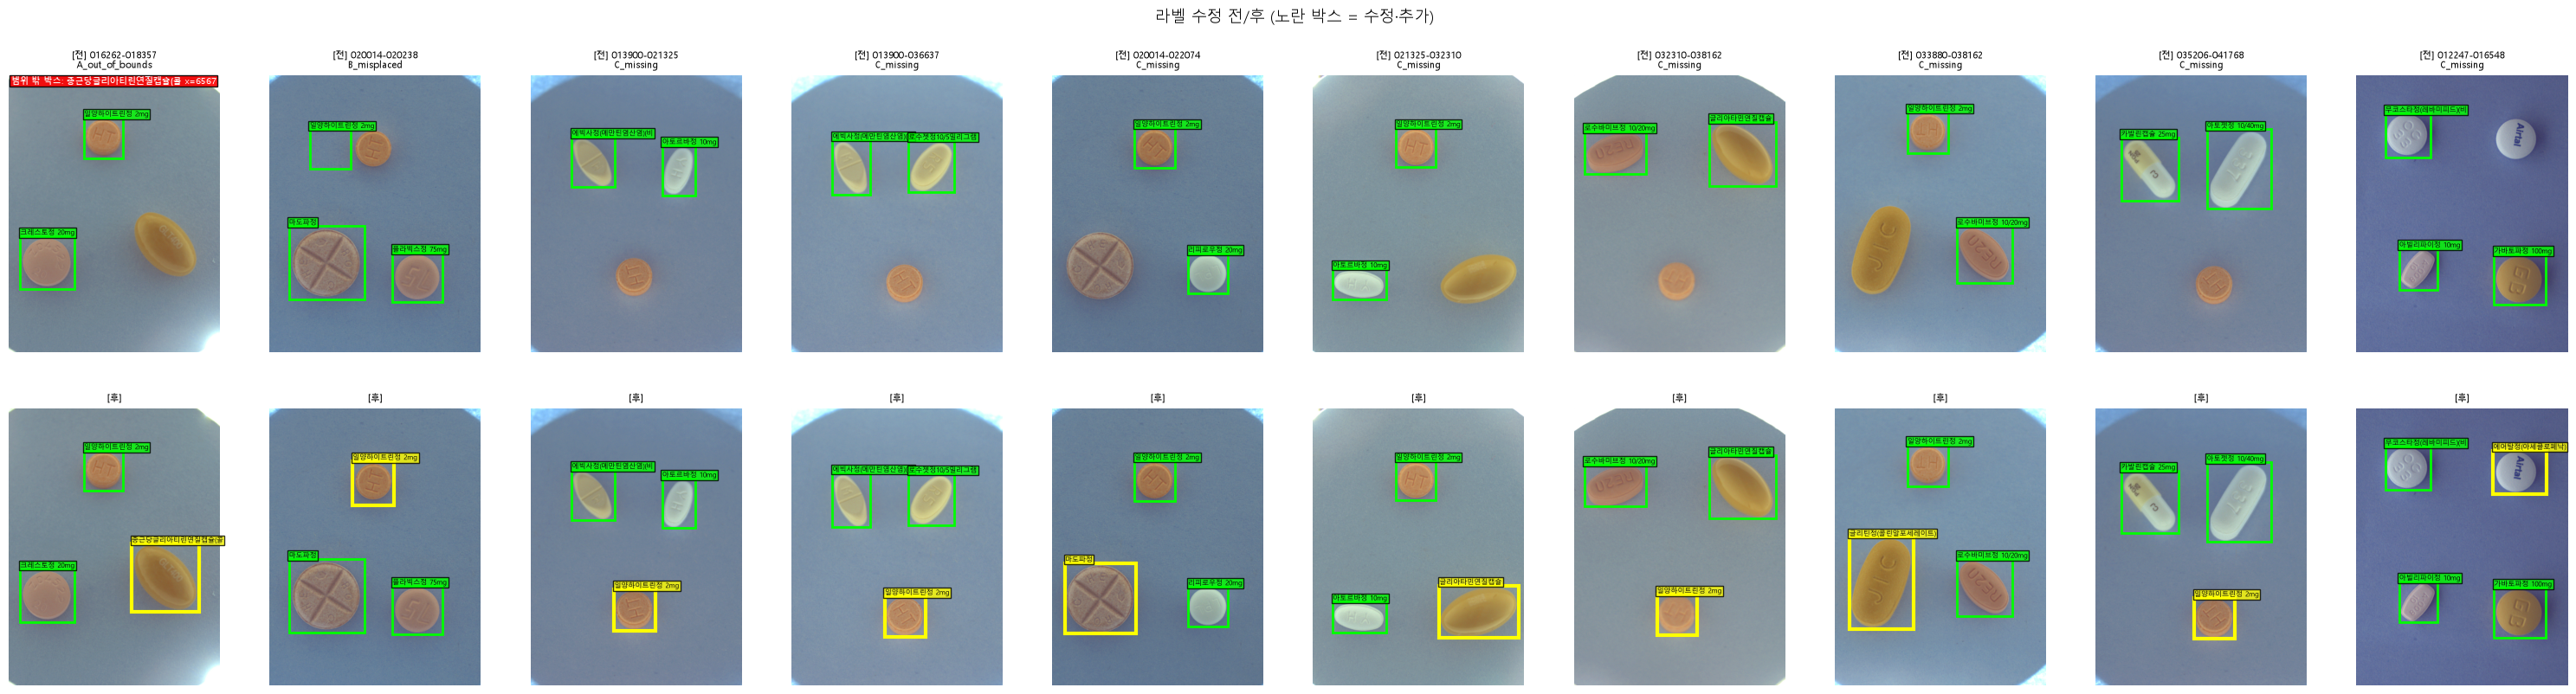

In [9]:
fixed_keys = set(zip(fix_log["file_name"], fix_log["category_id"]))
fix_files = list(dict.fromkeys(fix_log["file_name"]))
fig, axes = plt.subplots(2, len(fix_files), figsize=(3 * len(fix_files), 8.5))
for j, f in enumerate(fix_files):
    t = fix_log[fix_log["file_name"] == f]["type"].iloc[0]
    viz.draw_boxes(axes[0, j], P.train_img / f, raw[raw["file_name"] == f], NAME_COL, title=f"[전] {f.split('_')[0][-13:]}\n{t}")
    viz.draw_boxes(axes[1, j], P.train_img / f, clean[clean["file_name"] == f], NAME_COL, highlight=fixed_keys, title="[후]")
fig.suptitle("라벨 수정 전/후 (노란 박스 = 수정·추가)", fontsize=13)
plt.tight_layout()
save_fig(fig, "16_label_fixes_before_after")
plt.show()

## 5. 최종 무결성 검사
모든 조건을 `assert`로 확인한다. 하나라도 어긋나면 여기서 멈춘다.

In [10]:
show_source(check_integrity)
stats = check_integrity(clean, train_files)
print("✅ 모든 검사 통과")
print(f"박스 {len(raw)} → {len(clean)}개 / 출처 {stats['sources']} / 이미지당 박스 수 {stats['boxes_per_image']}")

**`src/pilldet/clean.py` → `check_integrity`**
```python
def check_integrity(clean: pd.DataFrame, train_files: list[str]) -> dict:
    """정제 결과의 무결성을 확인한다. 하나라도 어긋나면 AssertionError."""
    xyxy = to_xyxy(clean)
    per_img = clean.groupby("file_name")["category_id"].apply(sorted)
    assert set(per_img.index) == set(train_files), "라벨 없는 이미지가 있다"
    assert not out_of_bounds(xyxy, clean["img_w"].values, clean["img_h"].values).any(), "범위 밖 박스가 남아 있다"
    assert (clean["w"] > 0).all() and (clean["h"] > 0).all(), "크기 0 박스"
    assert not clean.duplicated(["file_name", "category_id"]).any(), "같은 이미지에 같은 클래스 중복"
    mismatch = [f for f, codes in per_img.items() if list(codes) != expected_codes(f)]
    assert not mismatch, f"파일명과 라벨 불일치: {mismatch}"
    return {"images": int(clean["file_name"].nunique()), "boxes": len(clean),
            "sources": clean["source"].value_counts().to_dict(),
            "boxes_per_image": clean.groupby("file_name").size().value_counts().to_dict()}
```

✅ 모든 검사 통과
박스 763 → 771개 / 출처 {'original': 762, 'added': 8, 'relocated': 1} / 이미지당 박스 수 {3: 157, 4: 75}


## 6. 클래스 번호 매핑
YOLO는 클래스 번호가 0부터 연속이어야 한다. 원래 `category_id`(약 코드) 순으로 0~55를 붙인다.
**제출 시에는 이 표로 다시 원래 코드로 되돌린다.**

In [11]:
class_map = build_class_map(clean)
class_map.to_csv(P.out / "class_map.csv", index=False, encoding="utf-8-sig")
print(f"클래스 {len(class_map)}개 → yolo_id 0~{len(class_map) - 1}")
class_map.head()

클래스 56개 → yolo_id 0~55


,yolo_id,category_id,dl_name,dl_name_en,n_boxes,n_images,n_combos
0,0,1900,보령부스파정 5mg,Buspar Tab. 5mg Boryung,15,15,5
1,1,2483,뮤테란캡슐 100mg,Muteran Cap. 100mg,9,9,3
2,2,3351,일양하이트린정 2mg,Hytrin Tab. 2mg Ilyang,157,157,89
3,3,3483,기넥신에프정(은행엽엑스)(수출용),Ginexin-F Tab.,45,45,15
4,4,3544,무코스타정(레바미피드)(비매품),Mucosta Tab.,6,6,2


## 7. 조합 단위 Stratified Group K-Fold
- **Group = 조합(combo)**: 같은 조합의 각도만 다른 사진이 train/val에 나뉘면 누수다. 조합 전체를 한 fold에 넣는다.
- **Stratify = 이미지의 가장 희귀한 클래스**: 희귀 클래스가 한 fold에 몰리지 않게 분산한다.
- 1개 조합에만 있는 클래스 17개는 구조적으로 train과 val 양쪽에 있을 수 없다. 그 클래스가 val에 있는 fold에서는 **처음 보는 약**이 된다.
  이건 결함이 아니라 *새로운 조합의 사진에 얼마나 일반화되는가* 를 정직하게 재는 것이다.
- 최종 제출 모델은 232장 **전체**로 학습한다. K-Fold는 실험 비교와 하이퍼파라미터 결정에 쓴다.

In [12]:
show_source(make_folds)
folds = make_folds(clean, N_FOLDS, SEED)
folds[["file_name", "combo", "camera_la", "fold"]].to_csv(P.out / "folds.csv", index=False, encoding="utf-8-sig")
print("✅ 누수 검사 통과 (조합이 fold 사이에 겹치지 않음)")
fold_summary(folds)

**`src/pilldet/split.py` → `make_folds`**
```python
def make_folds(clean: pd.DataFrame, n_folds: int = N_FOLDS, seed: int = SEED) -> pd.DataFrame:
    """이미지 단위 테이블(file_name, combo, camera_la, classes, rarest, fold)을 반환한다."""
    img = clean.groupby("file_name").agg(
        combo=("combo", "first"), camera_la=("camera_la", "first"),
        classes=("category_id", lambda s: sorted(s)),
    ).reset_index()
    freq = clean["category_id"].value_counts()
    img["rarest"] = img["classes"].apply(lambda cs: min(cs, key=lambda c: freq[c]))

    sgkf = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    img["fold"] = -1
    for k, (_, val_idx) in enumerate(sgkf.split(img, y=img["rarest"], groups=img["combo"])):
        img.loc[val_idx, "fold"] = k

    assert img.groupby("combo")["fold"].nunique().max() == 1, "조합이 여러 fold에 걸쳐 있다 (누수)"
    return img
```

✅ 누수 검사 통과 (조합이 fold 사이에 겹치지 않음)


C:\Users\user\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:1036: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


,fold,val_images,val_combos,val_boxes,val_classes,val_classes_unseen_in_train
0,0,47,23,156,33,5
1,1,46,22,153,33,3
2,2,46,23,150,29,1
3,3,46,22,153,32,7
4,4,47,24,159,33,3


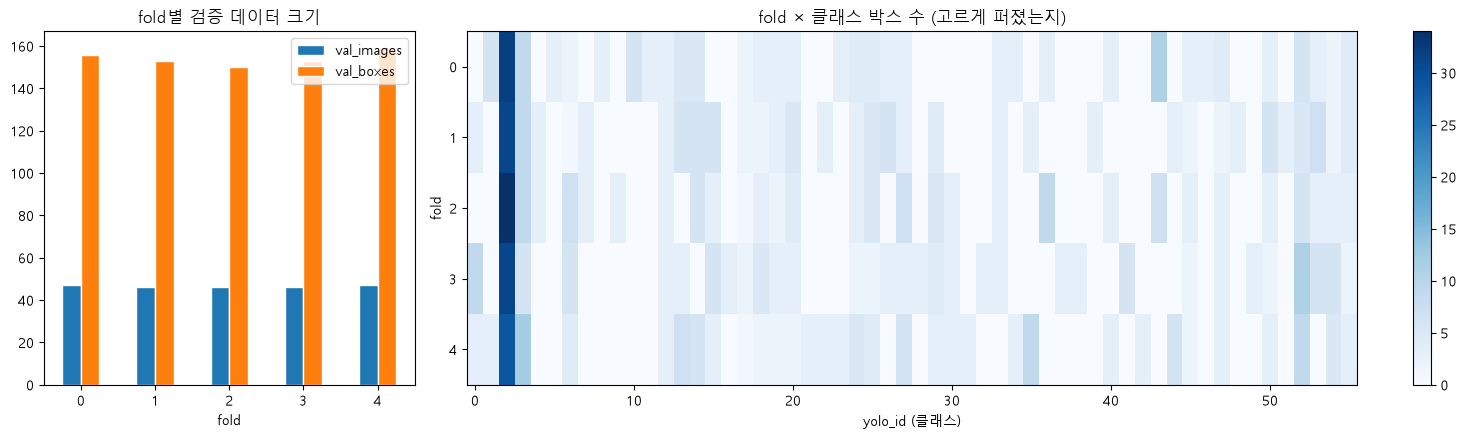

In [13]:
box_fold = clean.merge(folds[["file_name", "fold"]], on="file_name").merge(class_map[["category_id", "yolo_id"]], on="category_id")
ct = pd.crosstab(box_fold["yolo_id"], box_fold["fold"])
fs = fold_summary(folds)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1, 3]})
fs.set_index("fold")[["val_images", "val_boxes"]].plot(kind="bar", ax=axes[0], rot=0, edgecolor="white")
axes[0].set_title("fold별 검증 데이터 크기")
im = axes[1].imshow(ct.T.values, aspect="auto", cmap="Blues")
axes[1].set(xlabel="yolo_id (클래스)", ylabel="fold", title="fold × 클래스 박스 수 (고르게 퍼졌는지)")
axes[1].set_yticks(range(N_FOLDS))
fig.colorbar(im, ax=axes[1])
plt.tight_layout()
save_fig(fig, "17_fold_distribution")
plt.show()

## 8. 내보내기
### YOLO 형식
```
datasets/pill/
├── images/*.png          (원본 링크 또는 복사)
├── labels/*.txt          (class cx cy w h, 0~1 정규화)
├── fold{k}_train.txt / fold{k}_val.txt
├── data_fold{k}.yaml     (K-Fold 실험용)
└── data_full.yaml        (최종 학습용: 전체 학습, val은 fold0 – 모니터링 전용)
```
Ultralytics는 이미지 경로의 `/images/`를 `/labels/`로 바꿔 라벨을 찾기 때문에 이 구조를 따른다.
클래스 이름은 학습 그래프에서 글자가 깨지지 않게 영문명을 쓴다.

In [14]:
info = export_yolo(clean, folds, class_map, P.train_img, P.dataset)
print(f"이미지 {info['images']}장 ({info['link_mode']}) / 라벨 {info['labels']}개")
print(info["files"])
print((P.dataset / "data_fold0.yaml").read_text(encoding="utf-8")[:300], "...")

이미지 232장 (copy) / 라벨 232개
['all_train.txt', 'data_fold0.yaml', 'data_fold1.yaml', 'data_fold2.yaml', 'data_fold3.yaml', 'data_fold4.yaml', 'data_full.yaml', 'fold0_train.txt', 'fold0_val.txt', 'fold1_train.txt', 'fold1_val.txt', 'fold2_train.txt', 'fold2_val.txt', 'fold3_train.txt', 'fold3_val.txt', 'fold4_train.txt', 'fold4_val.txt']
path: C:\Users\user\Desktop\ai_15기\###프로젝트\pill-detection\datasets\pill
train: fold0_train.txt
val: fold0_val.txt
nc: 56
names:
  0: Buspar Tab. 5mg Boryung
  1: Muteran Cap. 100mg
  2: Hytrin Tab. 2mg Ilyang
  3: Ginexin-F Tab.
  4: Mucosta Tab.
  5: Aldrin Tab.
  6: Neuromed Tab. 800mg
  7: Airtal ...


### COCO 형식 (정제본)
다른 프레임워크(torchvision Faster R-CNN 등)와 pycocotools 평가에 쓰도록 **원래 약 코드**를 유지한 COCO 파일도 만든다.

In [15]:
coco_stats = export_coco(clean, class_map, train_files, P.out / "annotations_clean.json")
print("COCO:", coco_stats)

COCO: {'images': 232, 'annotations': 771, 'categories': 56}


### 왕복 검증
저장한 YOLO 라벨을 **다시 읽어 픽셀 좌표로 되돌리고** 정제 라벨과 비교한다. 변환 실수(가로·세로 뒤바뀜, 정규화 오류)를 잡는다.

In [16]:
err = verify_yolo_roundtrip(P.dataset, clean, class_map)
assert err < 0.01, err
print(f"✅ 왕복 검증 통과: 박스 {len(clean)}개, 최대 좌표 오차 {err:.5f}px")

✅ 왕복 검증 통과: 박스 771개, 최대 좌표 오차 0.00096px


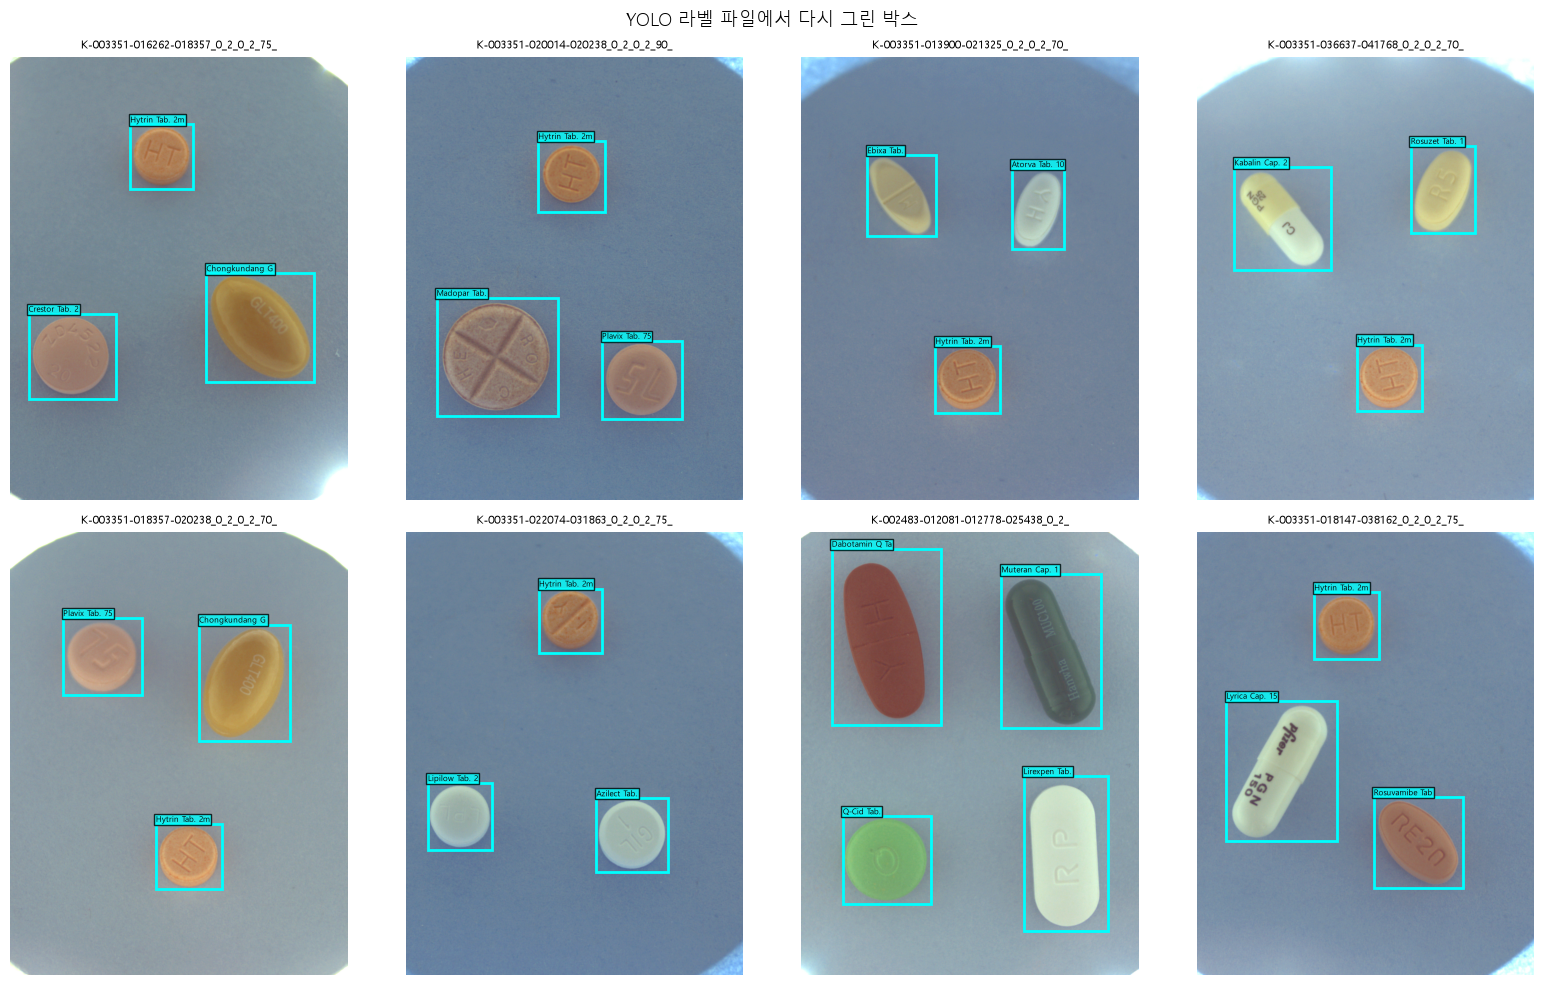

In [17]:
yolo_names = dict(zip(class_map["yolo_id"], class_map["dl_name_en"].str.strip()))
rng = np.random.default_rng(SEED)
show = list(fix_files[:3]) + list(rng.choice(train_files, 5, replace=False))
fig, axes = plt.subplots(2, 4, figsize=(16, 10))
for ax, f in zip(axes.flat, show):
    ax.imshow(Image.open(P.dataset / "images" / f))
    for line in (P.dataset / "labels" / f.replace(".png", ".txt")).read_text(encoding="utf-8").strip().splitlines():
        c, cx, cy, w, h = map(float, line.split())
        x, y, bw, bh = yolo_to_xywh(cx, cy, w, h, IMG_W, IMG_H)
        ax.add_patch(patches.Rectangle((x, y), bw, bh, fill=False, ec="cyan", lw=2))
        ax.text(x, y - 6, yolo_names[int(c)][:14], fontsize=6, bbox=dict(fc="cyan", alpha=0.8, pad=1))
    ax.set_title(f[:34], fontsize=8)
    ax.axis("off")
fig.suptitle("YOLO 라벨 파일에서 다시 그린 박스", fontsize=13)
plt.tight_layout()
save_fig(fig, "18_yolo_export_check")
plt.show()

## 9. 요약

| 항목 | 결과 |
|---|---|
| 라벨 정제 | 범위 밖 박스 복원 1, 엉뚱한 위치 박스 이동 1, 누락 박스 추가 8. 모든 수정은 `label_fixes.csv`에 기록 |
| 무결성 | 모든 이미지에서 파일명의 약 목록 = 라벨 약 목록, 범위 밖·중복 박스 0 |
| 검증 분할 | 조합 단위 Stratified Group 5-Fold, 조합 누수 0 |
| 산출물 | YOLO 데이터셋 + fold별 yaml, COCO 정제본, `class_map.csv`, `folds.csv` |

**다음 단계 (03_baseline)**: `data_fold0.yaml`로 YOLO 베이스라인 → 첫 Kaggle 제출 → 개선 실험